# Spiral arms as shocks in a galactic gas disk
**Astrophysical Fluid Dynamics: final mini-project** · Aryana Haghjoo

**Question.** In density-wave theory, spiral arms are a pattern that rotates slower than the gas, so gas flows *through* the arms. What does the gas do when it hits an arm?

**Answer, in one line.** The inflow into the arm is supersonic, so the gas **shocks**. This forms the narrow, dense arms where stars are born (Roberts 1969).

**The backbone is the HW2 code.** The finite-volume MUSCL–Hancock solver I wrote for the Kelvin–Helmholtz assignment (`kh_sim.py`) is reused here, imported unchanged: gradients, slope limiter, face extrapolation and the conservative flux update. `spiral_sim.py` adds the galaxy physics on top of it.

| from HW2 (`kh_sim.py`, unchanged) | new for this project (`spiral_sim.py`) |
|---|---|
| `gradient`: central-difference slopes | isothermal EOS $P = c_s^2\rho$ (no energy equation) |
| `slope_limit`: limiter at sharp jumps | Rusanov flux for the isothermal system |
| `to_faces`: linear reconstruction to faces | gravity: flat rotation curve + rotating 2-armed spiral |
| `apply_fluxes`: conservative update | Coriolis + centrifugal (frame co-rotating with the pattern) |
| CFL time step, half-step predictor (same structure) | sponge zones at the centre and box edge |

**Units.** $v_0=1$ (flat rotation speed) and $r$ is in units of $R_0$. With $R_0=10$ kpc and $v_0=220$ km/s, one time unit is 44 Myr and $c_s=0.05$ is about 11 km/s.

In [1]:
import numpy as np, pickle, gzip, time
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Image, display
import spiral_sim as S, shock_test as ST

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
R = pickle.load(gzip.open('results_spiral.pkl.gz', 'rb'))      # all production runs (made by experiments.py, ~30 min)
EXT, CM = [-1.1, 1.1, -1.1, 1.1], 'inferno'
def show(ax, rho, title='', lim=1.0):
    im = ax.imshow(np.log10(rho).T, origin='lower', extent=EXT, cmap=CM, vmin=-0.6, vmax=0.9)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    return im

## 1. Setup
- **Gas:** a 2D, isothermal ($c_s = 0.05$), initially uniform disk in circular rotation, between $r = 0.15$ and $r = 1$.
- **Axisymmetric potential:** $\Phi_0=\tfrac12\ln(r^2+r_c^2)$, which gives a flat rotation curve.
- **Spiral perturbation:** a two-armed logarithmic spiral (trailing, pitch angle $i = 20°$),
  $$\Phi_1 = \epsilon\cos\!\left[2\phi + 2\cot i\,\ln r\right].$$
  Its strength is set by $F$, the arm's radial force as a fraction of the axisymmetric force (fiducial $F = 5\%$). It is ramped up over $t = 3$.
- **Frame:** we work in the frame rotating with the pattern speed $\Omega_p = 0.9$. That puts the inner Lindblad resonance (ILR) at $r = 0.33$ and corotation at $r = 1.11$, so the gas disk sits between them, where density-wave theory says arms live.

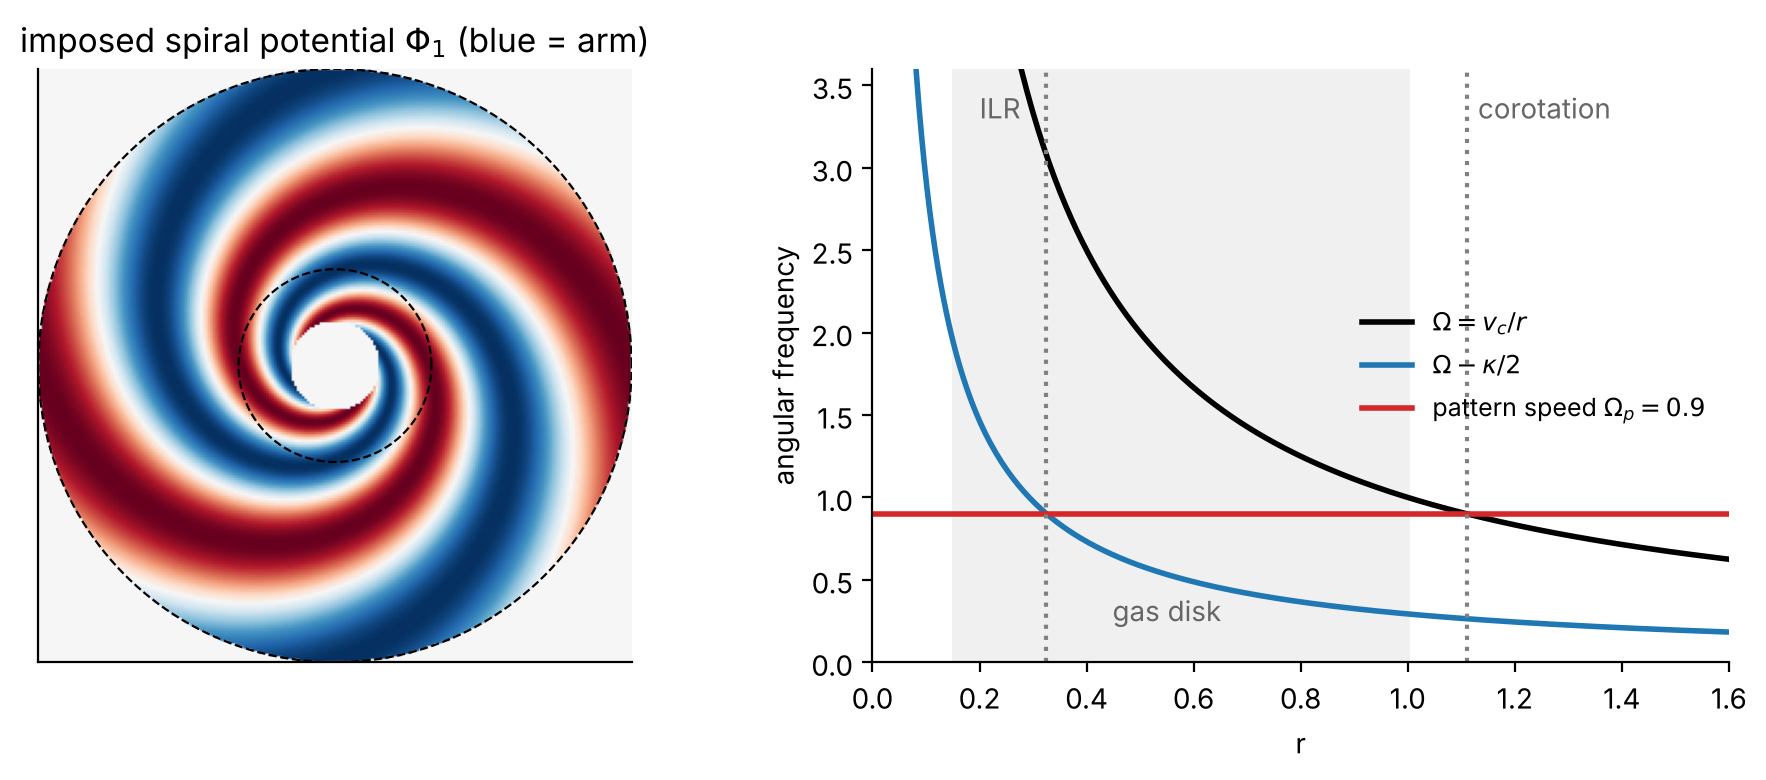

In [2]:
display(Image('fig_setup.png', width=800))

## 2. Verification: does the solver get isothermal shocks right?
Before trusting the galaxy, I test the solver on a problem with an exact answer: two streams colliding at $\pm U$. Two shocks run outward, and the gas between them is at rest. The jump conditions (A.13, with $\gamma \to 1$) give $D = \rho_2/\rho_1 = \mathcal{M}_1^2$.

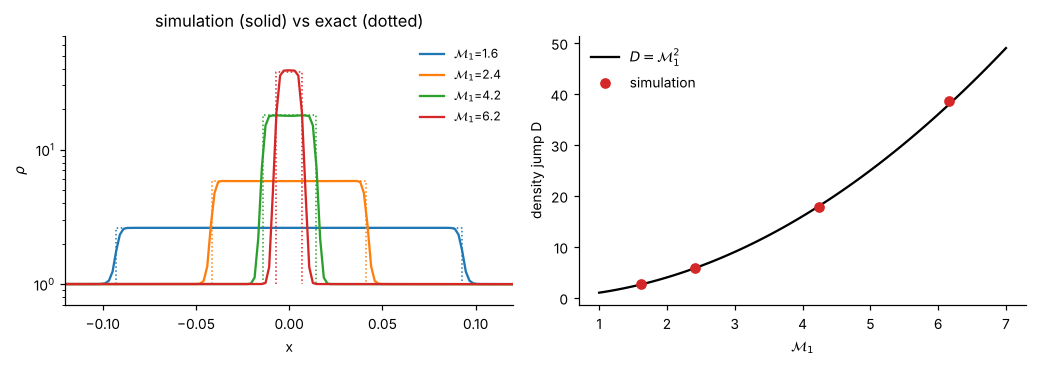

M1 = 1.62:  exact D =   2.62   simulated =   2.62   (+0.0%)
M1 = 2.41:  exact D =   5.83   simulated =   5.83   (-0.0%)
M1 = 4.24:  exact D =  17.94   simulated =  17.87   (-0.4%)
M1 = 6.16:  exact D =  37.97   simulated =  38.67   (+1.8%)


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for v, c in zip(R['shocktest'], ['C0', 'C1', 'C2', 'C3']):
    ax[0].semilogy(v['x'], v['rho'], c=c, lw=1.5, label=fr"$\mathcal{{M}}_1$={v['M1']:.1f}")
    xs = v['Vs'] * v['T']; ax[0].semilogy([-xs, -xs, xs, xs], [1, v['rho2_exact'], v['rho2_exact'], 1], c=c, ls=':', lw=1)
ax[0].set_xlim(-0.12, 0.12); ax[0].set_ylim(0.7, 70); ax[0].set_xlabel('x'); ax[0].set_ylabel(r'$\rho$'); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title('simulation (solid) vs exact (dotted)')
M = np.linspace(1, 7, 100); ax[1].plot(M, M**2, 'k', label=r'$D=\mathcal{M}_1^2$')
ax[1].plot([v['M1'] for v in R['shocktest']], [v['rho2_sim'] for v in R['shocktest']], 'C3o', label='simulation')
ax[1].set_xlabel(r'$\mathcal{M}_1$'); ax[1].set_ylabel('density jump D'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
for v in R['shocktest']:
    print(f"M1 = {v['M1']:.2f}:  exact D = {v['rho2_exact']:6.2f}   simulated = {v['rho2_sim']:6.2f}   ({100*(v['rho2_sim']/v['rho2_exact']-1):+.1f}%)")

The density jump is right to within 2% up to $\mathcal{M}_1 \approx 6$. The shocks are captured in about 3 cells.

## 3. Try it yourself: a quick live run
A low-resolution run takes about 10 s. Change `F`, `cs`, `pitch_deg` or `Omega_p` and rerun.

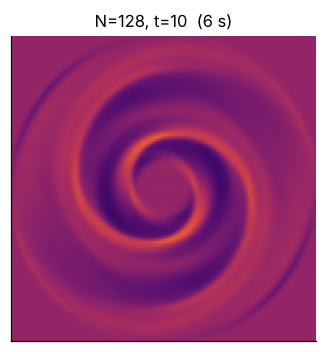

In [4]:
t0 = time.time()
g = S.Galaxy(N=128, F=0.05, cs=0.05, pitch_deg=20, Omega_p=0.9)
g.run(10.0)
fig, ax = plt.subplots(figsize=(3.6, 3.6)); show(ax, g.primitives()[0], f'N=128, t=10  ({time.time()-t0:.0f} s)'); plt.show()

## 4. Movie of the fiducial run
$N = 256^2$, $F = 5\%$, $c_s = 0.05$, $t = 0 \to 20$ (about 0.9 Gyr). Each frame is $\Delta t = 0.2$, about 9 Myr. The view is in the frame rotating with the spiral pattern: the arms stay put while the gas streams through them counter-clockwise.

In [5]:
fr = R['fid']['frames']; times = sorted(fr)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
im = show(ax, fr[times[0]], lim=1.0); title = ax.set_title('')
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.92)
def update(i):
    im.set_data(np.log10(fr[times[i]]).T); title.set_text(f't = {times[i]:.1f}  ({times[i]*44:.0f} Myr)')
    return im, title
anim = animation.FuncAnimation(fig, update, frames=len(times), interval=70)
anim.save('spiral_movie.mp4', writer=animation.FFMpegWriter(fps=15, bitrate=2400), dpi=130)
anim.save('spiral_movie.gif', writer=animation.PillowWriter(fps=15), dpi=70)
plt.close(fig)
HTML(anim.to_html5_video())

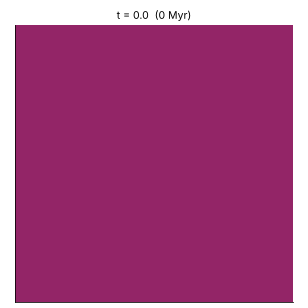

In [6]:
display(Image(filename='spiral_movie.gif'))   # same movie as a GIF, for viewers without video

## 5. Snapshots and the flow pattern

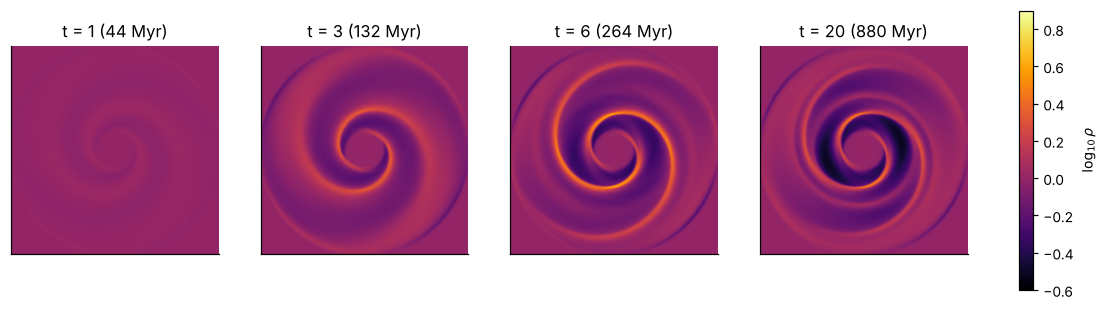

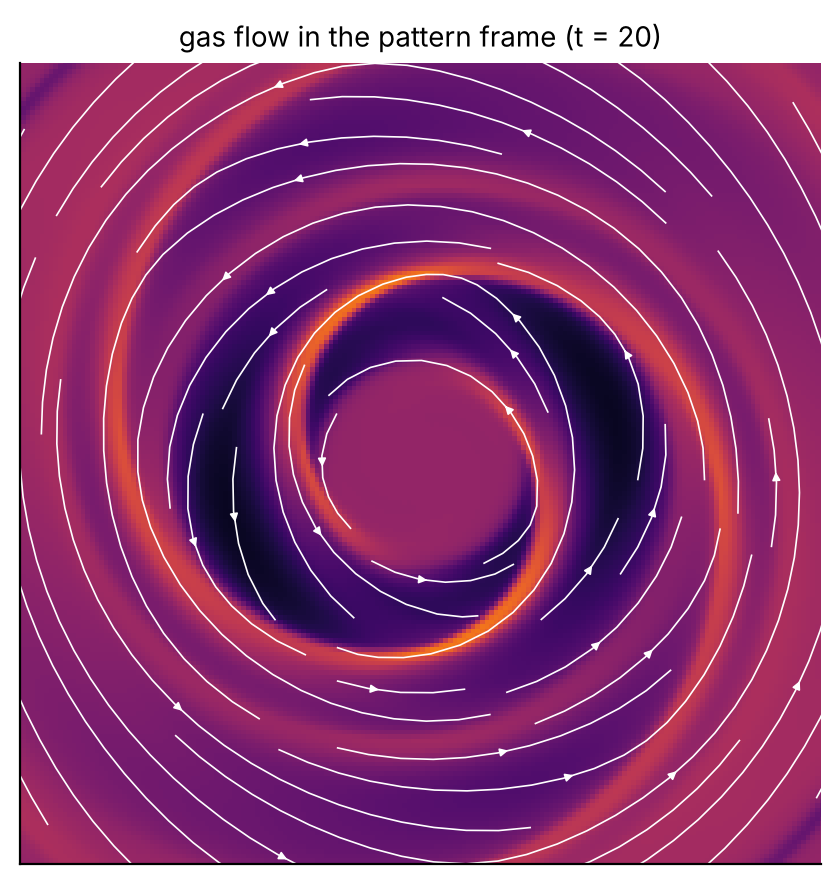

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for a, t in zip(axs, [1.0, 3.0, 6.0, 20.0]):
    im = show(a, fr[t], f't = {t:g} ({t*44:.0f} Myr)')
fig.colorbar(im, ax=axs, fraction=0.015, label=r'$\log_{10}\rho$'); plt.show()
display(Image('fig_streamlines.png', width=430))

- **Arms form within one ramp time** (about 130 Myr), then settle into a quasi-steady pattern. Some oscillation remains; see Section 9.
- **Streamlines:** the gas circulates through the pattern. It speeds up through the low-density inter-arm region, then turns sharply where it crosses an arm. That sudden deflection is the oblique shock from A.14.
- **Arm vs inter-arm:** narrow, dense arms alternate with broad, rarefied inter-arm regions.

## 6. How strong does the spiral potential need to be?

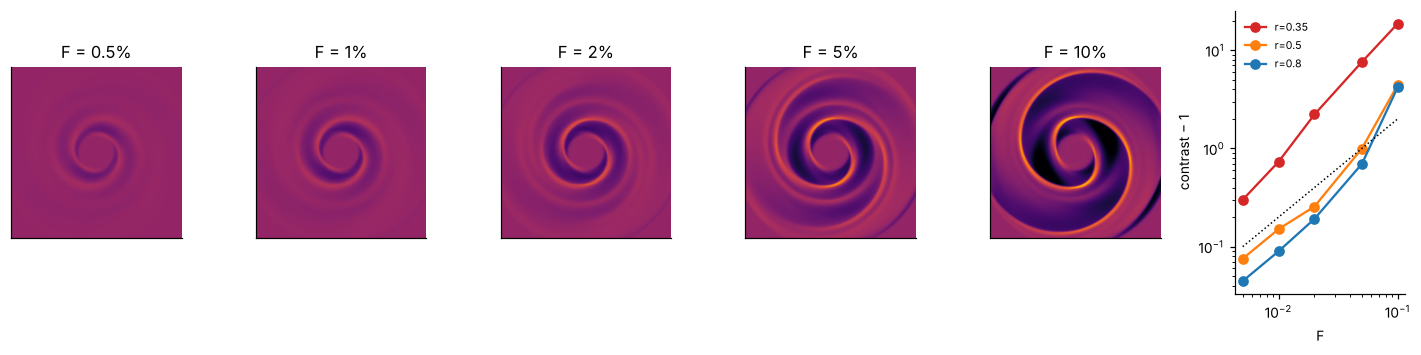

In [8]:
Fs = [0.005, 0.01, 0.02, 0.05, 0.1]
fig = plt.figure(figsize=(13, 3.3))
for k, F in enumerate(Fs):
    show(fig.add_subplot(1, 6, k+1), R[('F', F)]['rho'], f'F = {100*F:g}%', lim=0.9)
a = fig.add_subplot(1, 6, 6)
for rr, c in [(0.35, 'C3'), (0.5, 'C1'), (0.8, 'C0')]:
    a.loglog(Fs, [R[('F', F)]['rings'][rr]['max']/R[('F', F)]['rings'][rr]['min'] - 1 for F in Fs], 'o-', c=c, label=f'r={rr}')
a.loglog([0.005, 0.1], [0.1, 2], 'k:', lw=1); a.set_xlabel('F'); a.set_ylabel('contrast − 1'); a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

- **Weak forcing ($F \lesssim 1\%$):** the gas response is a gentle, sinusoidal density wave, and the contrast grows roughly $\propto F$, as in linear theory.
- **Stronger forcing:** the response grows **faster than linearly** and the arms narrow into sharp fronts. This is nonlinear steepening into shocks.
- **$F = 5$–$10\%$:** this is typical of real spiral galaxies, and it gives arm/inter-arm contrasts of order 10 in the inner disk.

## 7. Where do arms shock? The inflow Mach number
In the pattern frame, gas arrives at an arm with normal velocity $u_\perp \approx (v_c - \Omega_p r)\sin i$. Shocks need $\mathcal{M}_\perp = u_\perp/c_s > 1$.

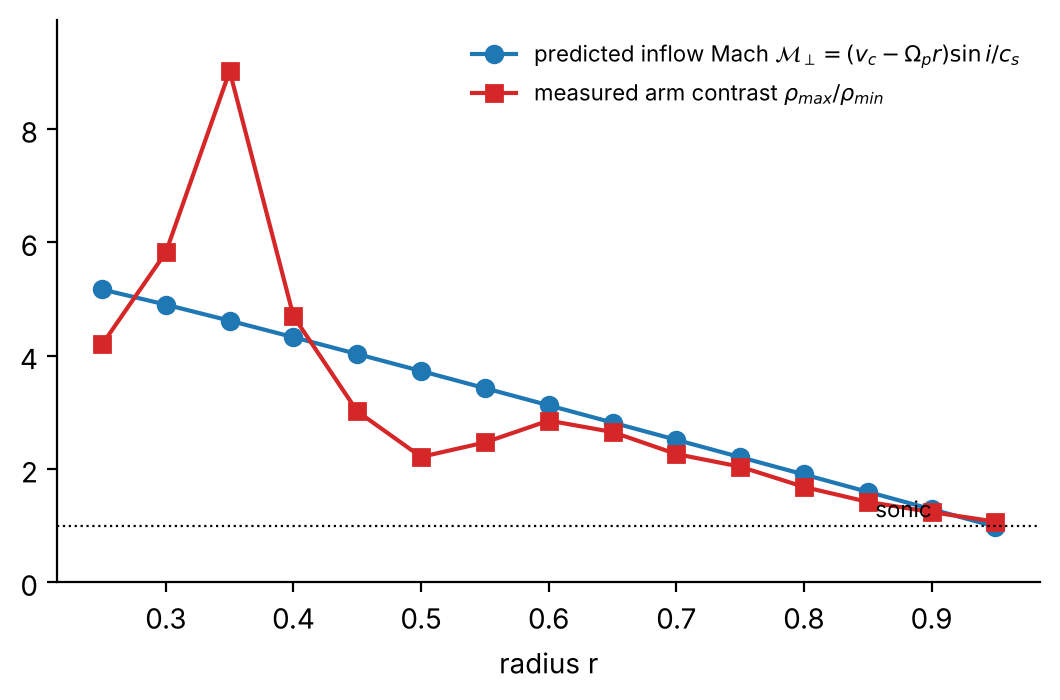

In [9]:
display(Image('fig_radial.png', width=560))

- **Inflow is supersonic out to $r \approx 0.94$**, so the arms there are shocks. Their strength follows $\mathcal{M}_\perp$, falling toward the edge.
- **The arms fade as $\mathcal{M}_\perp \to 1$ near corotation**, because there the gas co-moves with the pattern.
- **The strongest response is near $r \approx 0.35$, next to the inner Lindblad resonance**, where the gas's epicyclic motion resonates with the forcing.

## 8. Anatomy of an arm, and the effect of gas temperature

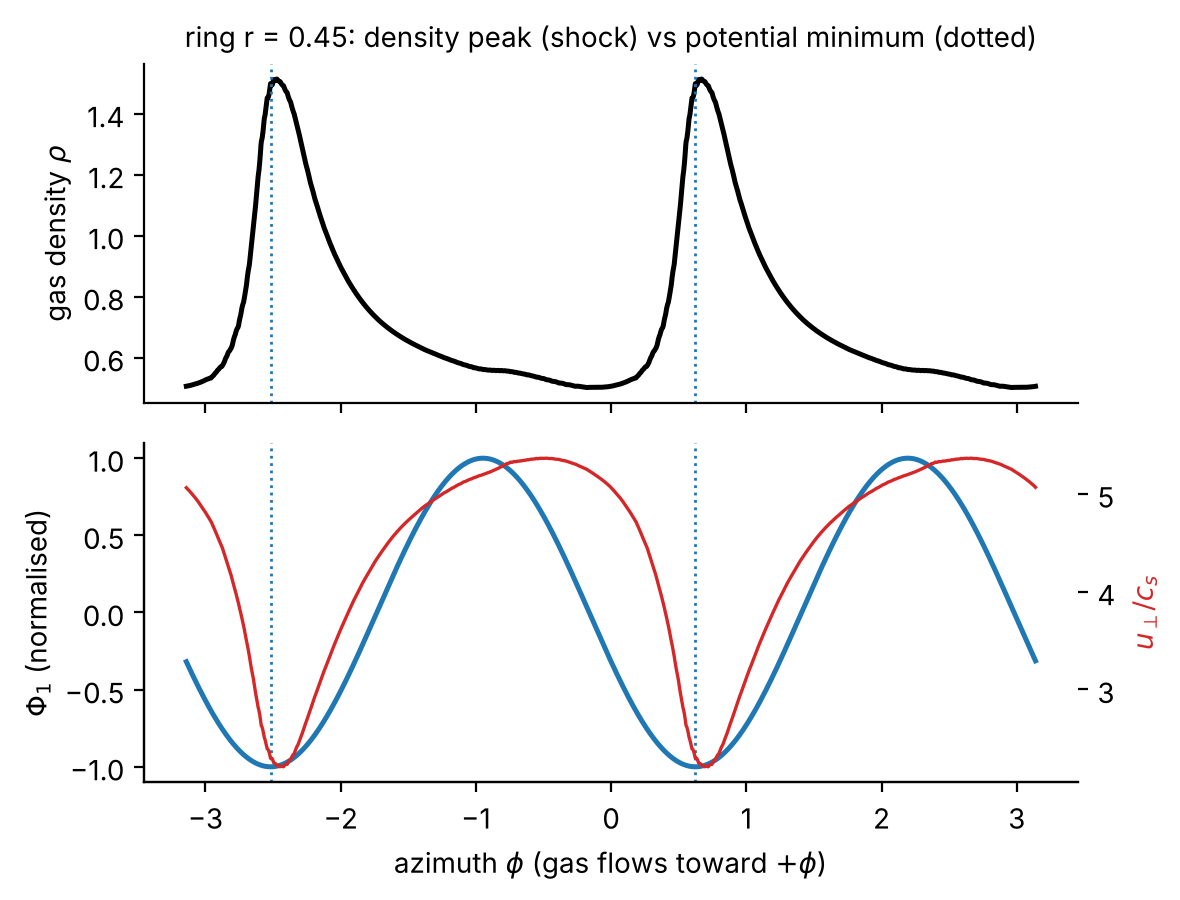

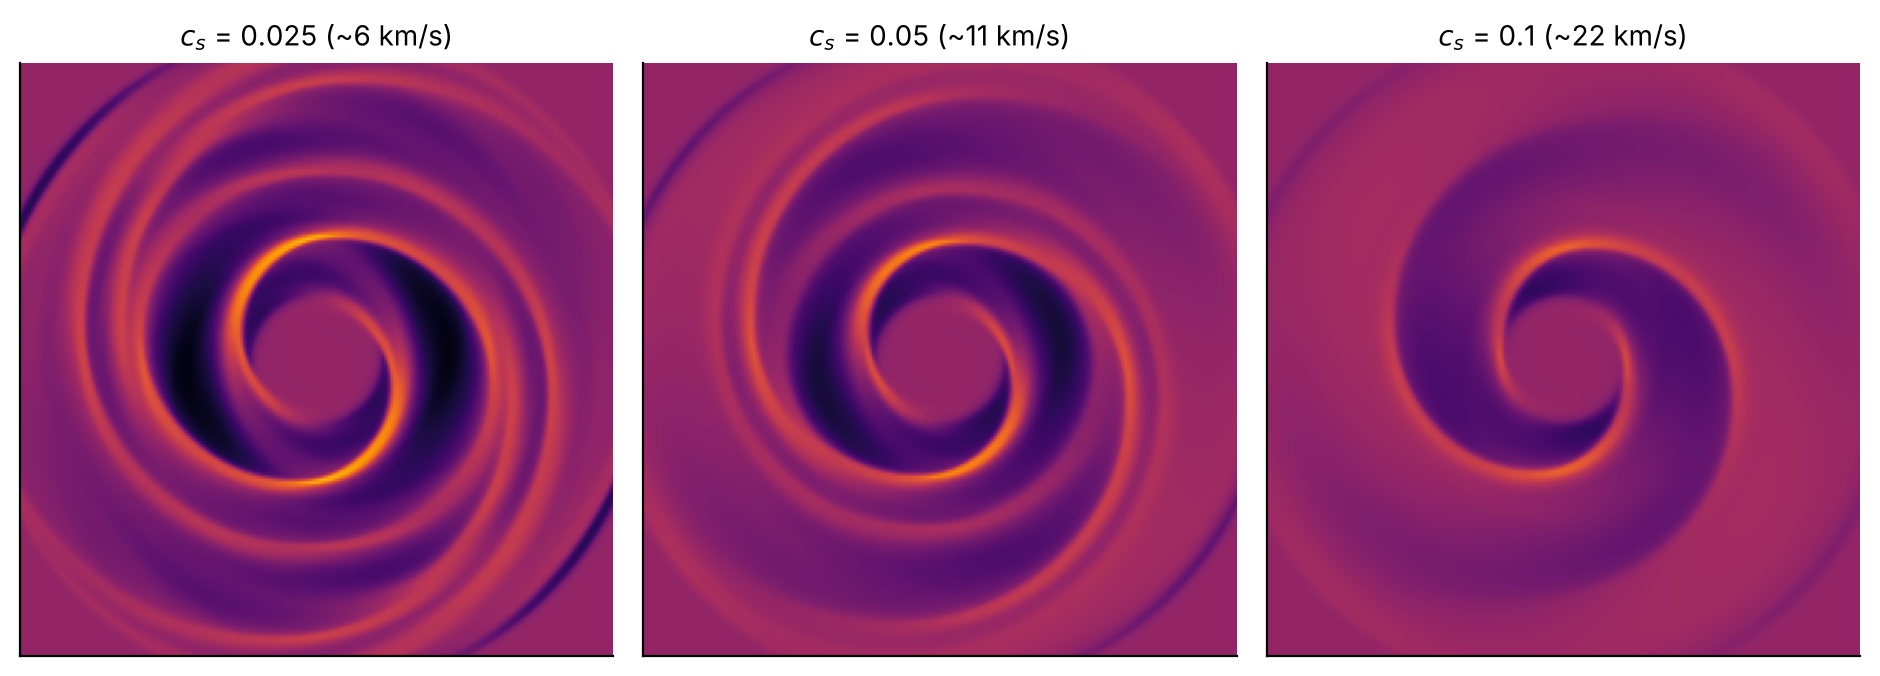

In [10]:
display(Image('fig_profile.png', width=560)); display(Image('fig_cs.png', width=820))

- **Arm profile (ring at $r = 0.45$):** the density rises steeply on the side where gas enters. At the same place, the normal velocity $u_\perp$ drops abruptly: that's the shock. Downstream, the density relaxes slowly as the gas re-accelerates out of the potential well. The asymmetric, saw-tooth profile is the signature of a shock, unlike the symmetric sinusoid of a linear wave.
- **Gas temperature:** colder gas (lower $c_s$, higher $\mathcal{M}$) makes sharper, denser arms. Warm gas at about 22 km/s barely shocks. This is why arms are traced by the cold, dense phase of the ISM.

## 9. Numerics: resolution and time evolution

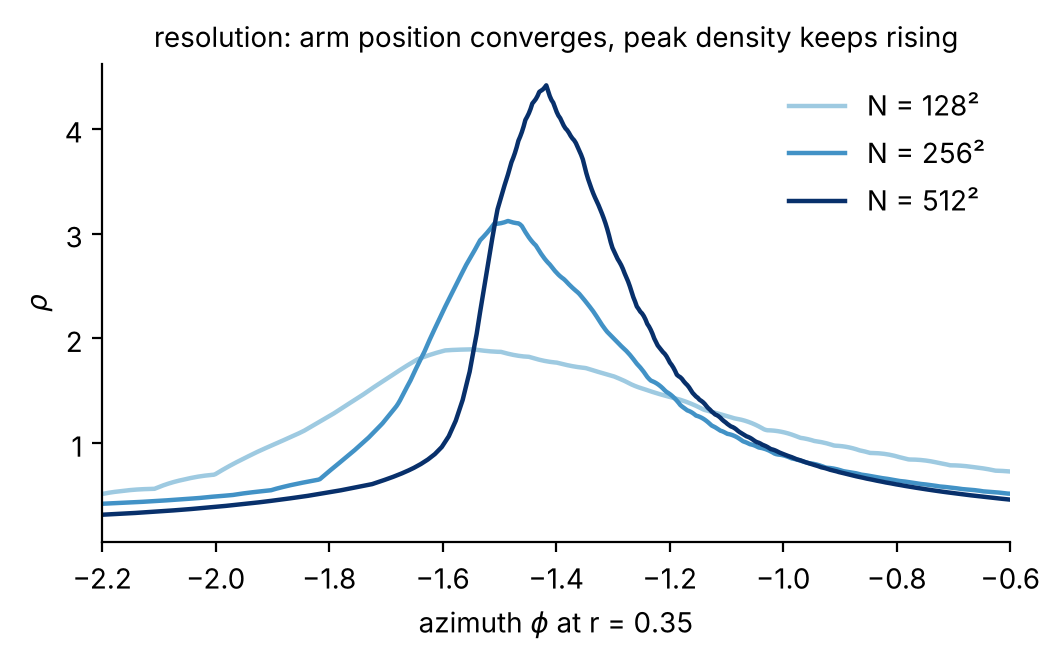

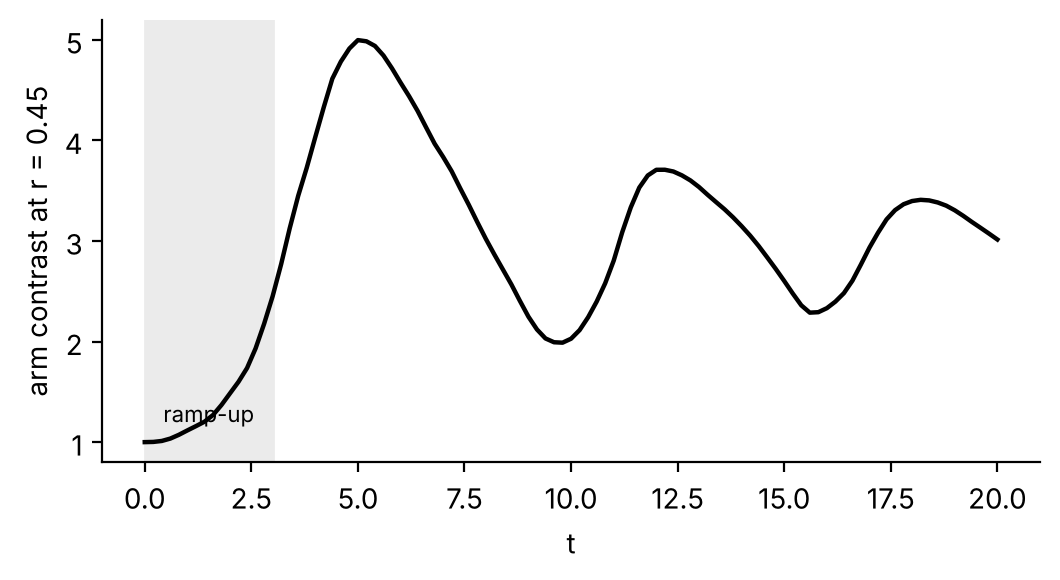

N=128: peak density on ring r=0.35 = 1.90
N=256: peak density on ring r=0.35 = 3.12
N=512: peak density on ring r=0.35 = 4.42


In [11]:
display(Image('fig_resolution.png', width=520)); display(Image('fig_time.png', width=520))
for N in (128, 256, 512):
    print(f"N={N}: peak density on ring r=0.35 = {R[('N', N)]['rings'][0.35]['max']:.2f}")

- **Arm position converges with resolution.** The **peak density does not**: it keeps rising, 1.9 → 3.1 → 4.4. The shock is captured in a fixed number of cells, so a finer grid makes it thinner and denser. This is the same numerical-diffusion story as the KH growth rate in HW2, where the Rusanov flux smears sharp features.
- **The pattern is quasi-steady.** After the ramp the arm contrast overshoots, then shows a damped oscillation with a period of about 6.5 time units (about 290 Myr) as the disk settles.

## Takeaways
1. A **finite-volume solver from HW2**, with gravity, rotation and an isothermal EOS added, reproduces the classic result: **gas shocks at spiral arms**.
2. **Verified against exact isothermal shocks**: $D = \mathcal{M}^2$ to within 2%.
3. **Arm strength is set by the inflow Mach number** $\mathcal{M}_\perp$: arms are strong in the inner disk and fade toward corotation. They are sharper for colder gas and stronger forcing, with linear behaviour below $F \sim 1\%$.

**Limitations and next steps.**
- The spiral potential is **imposed**, not self-consistent: there is no self-gravity and no stars.
- The gas is isothermal and has no cooling or star formation.
- The grid is fixed and Cartesian: not Galilean invariant, and peak densities are not converged.
- Next steps: add gas self-gravity (a Poisson solve by FFT) to let arms form on their own (Toomre $Q$), and compare with a moving-mesh code.